In [36]:
# imports

from pacha.utils import file_utils as futils
from pacha.visualisation import geospatial as gvis
from pacha.visualisation import statistical as svis
from pacha.utils import geospatial as gutils
from pacha.utils import instruments as iutils
from pacha.utils import scores as sutils
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt

import re
import pandas as pd
from pathlib import Path

In [34]:
def rad_vals_at_stations(ds, stations, gauges, varname='dBZ'):
    dfs = []
    for station in stations:
        point = gauges.get_coords_station(station)
        df = gutils.ds_to_df_at_point(ds, point)[[varname]]
        dfs.append(df.rename(columns={varname: f'{station}_{varname}'}))
    return pd.concat(dfs, axis=1)

def radar_files_to_df(fpaths):
    rows = []

    pattern = (
        r"l(\d+)_radar_(\d{4})_(\d{2})_(\d{2})_"
        r"(\d{6})-(\d{6})_step([\d.]+)min_n(\d+)_(\w+)\.nc"
    )

    for path in fpaths:
        match = re.fullmatch(pattern, Path(path).name)
        if not match:
            continue

        level, year, month, day, start, end, step, nsteps, sampling = match.groups()

        date = f"{year}-{month}-{day}"
        start_time = pd.Timestamp(f"{date} {start[:2]}:{start[2:4]}:{start[4:]}")
        end_time = pd.Timestamp(f"{date} {end[:2]}:{end[2:4]}:{end[4:]}")

        if end_time < start_time:
            end_time += pd.Timedelta(days=1)

        step = float(step)
        nsteps = int(nsteps)

        rows.append({
            "path": str(path),
            "date": pd.Timestamp(date),
            "level": int(level),
            "start": start_time,
            "end": end_time,
            "step_min": step,
            "nsteps": nsteps,
            "sampling": sampling,
            "completion": 100 * nsteps / (1440 / step),
        })

    return pd.DataFrame(rows).sort_values("date").reset_index(drop=True).set_index('date')

In [26]:
qpe_dir = '../data/processed/l2_radar/'

fpaths = futils.get_fpaths_from_dir(qpe_dir)

df = radar_files_to_df(fpaths)
df.head()

,path,level,start,end,step_min,nsteps,sampling,completion
date,,,,,,,,
2023-04-01,../data/processed/l2_radar/l2_radar_2023_04_01...,2,2023-04-01 00:07:59,2023-04-02 00:00:11,8.90000,162,irregular,100.125000
2023-04-02,../data/processed/l2_radar/l2_radar_2023_04_02...,2,2023-04-02 00:09:06,2023-04-03 00:01:17,8.90000,162,irregular,100.125000
2023-04-03,../data/processed/l2_radar/l2_radar_2023_04_03...,2,2023-04-03 00:10:13,2023-04-04 00:03:25,8.89167,164,irregular,101.266242
2023-04-04,../data/processed/l2_radar/l2_radar_2023_04_04...,2,2023-04-04 00:12:18,2023-04-05 00:04:19,8.89167,162,irregular,100.031287
2023-04-05,../data/processed/l2_radar/l2_radar_2023_04_05...,2,2023-04-05 00:13:13,2023-04-06 00:03:11,8.90000,142,irregular,87.763889


In [32]:
gauges_data_path = '/media/admingosset/T7Shield/data/processed_data/ceara/gauges/v0/gauges_10min_utc.csv'
gauges_metadata_path = '/media/admingosset/T7Shield/data/processed_data/ceara/gauges/v0/gauges_10min_utc_metadata.csv'

gauges = iutils.Gauges(gauges_data_path, gauges_metadata_path)


l1_rad_dir = '/home/admingosset/WORK/projects/funceme-radar-qpe/data/processed/l1_radar/'
gauges_data_path = '/media/admingosset/T7Shield/data/processed_data/ceara/gauges/v0/gauges_10min_utc.csv'
gauges_metadata_path = '/media/admingosset/T7Shield/data/processed_data/ceara/gauges/v0/gauges_10min_utc_metadata.csv'

gauges = iutils.Gauges(gauges_data_path, gauges_metadata_path)
df_fpaths_l1rad = futils.get_df_dates_filepaths(
    l1_rad_dir, date_char_st=9, date_char_nd=19, date_format='%Y_%m_%d'
)

with xr.open_dataset(df_fpaths_l1rad.iloc[0, 0]) as sample_ds:
    lon0, lat0 = gutils.calc_ds_center(sample_ds)

print(f'Radar center: ({lon0}, {lat0})')

Radar center: (-39.26805152577293, -5.070284552413706)


minimal accepted steps per day (0.8): 115


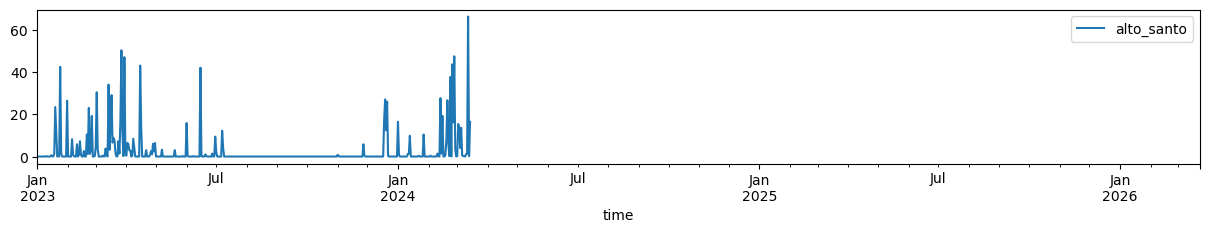

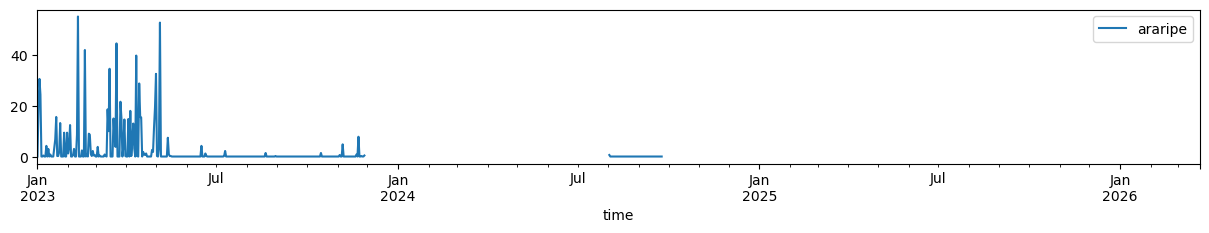

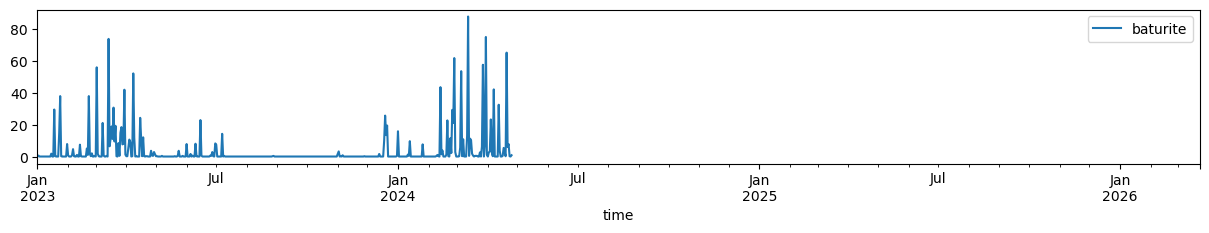

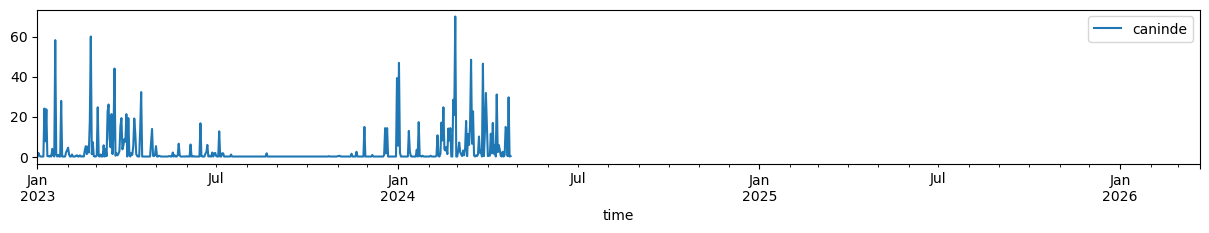

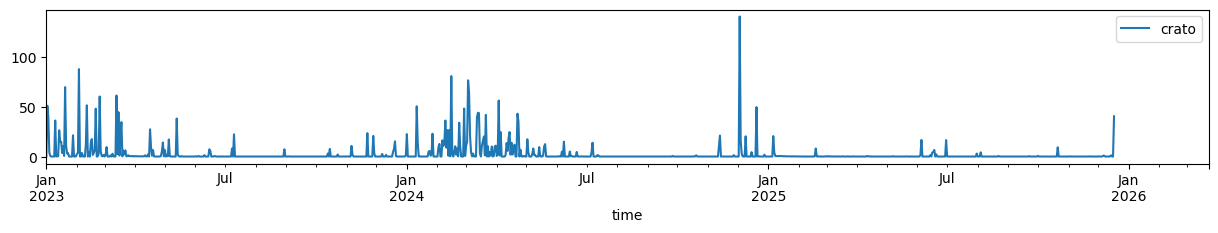

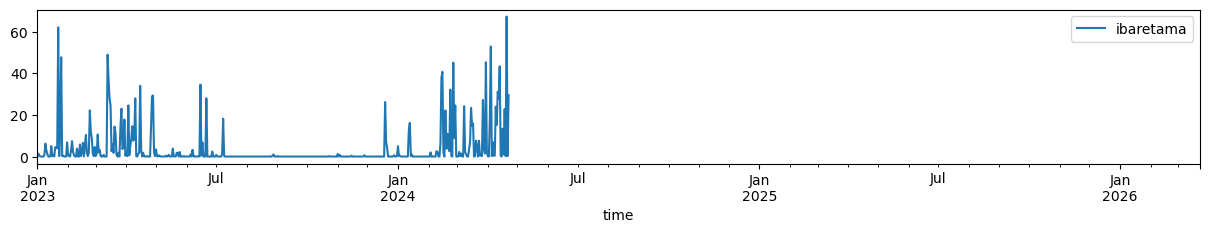

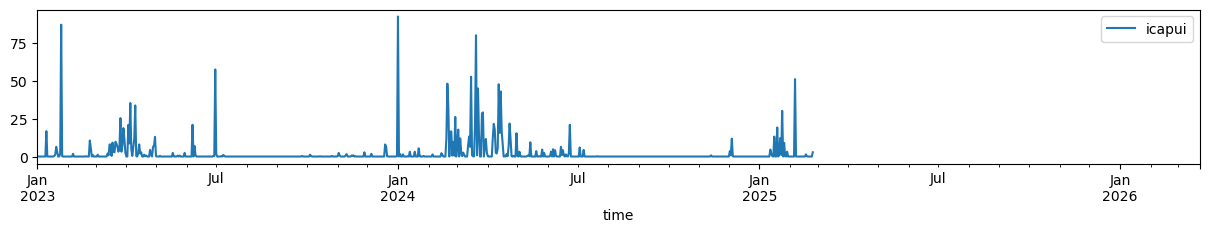

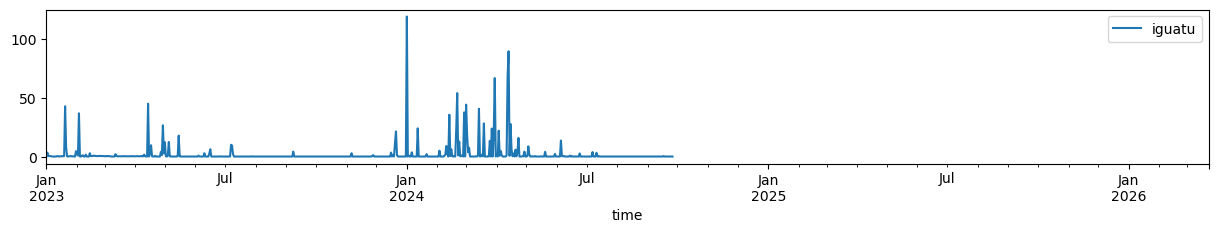

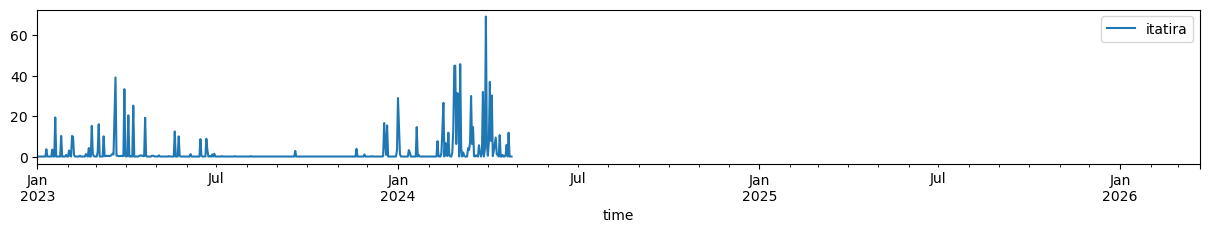

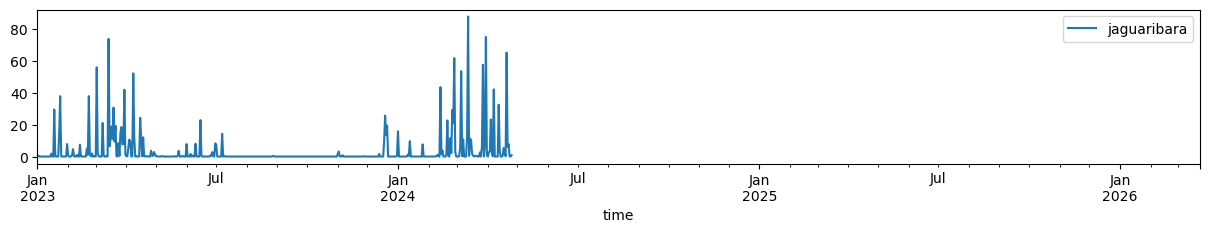

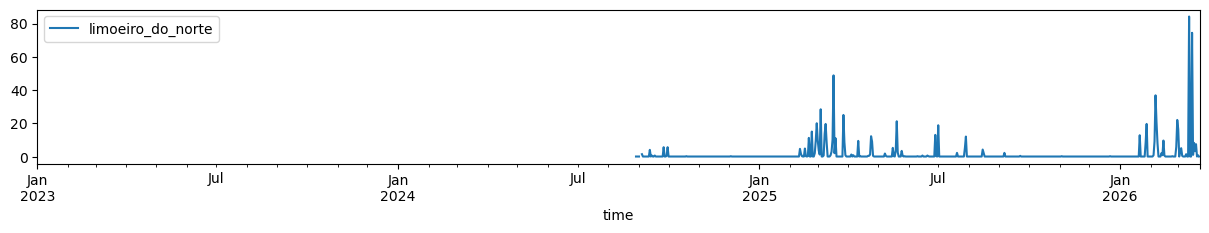

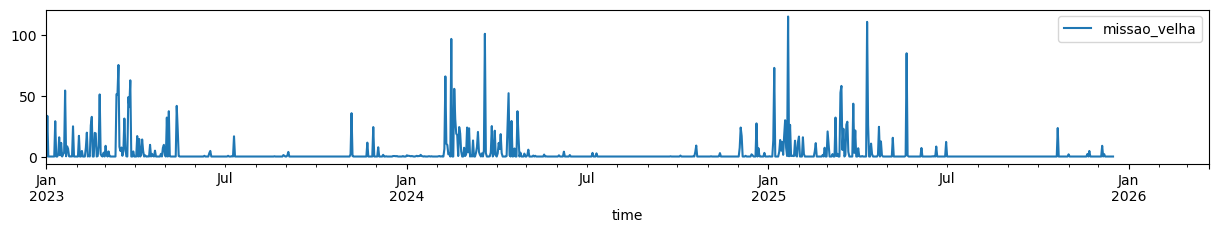

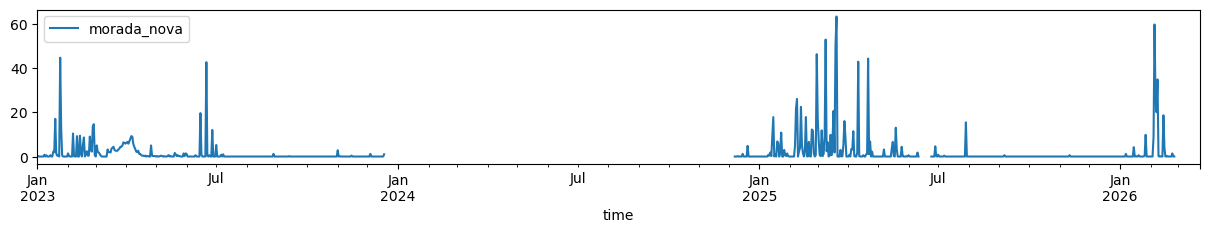

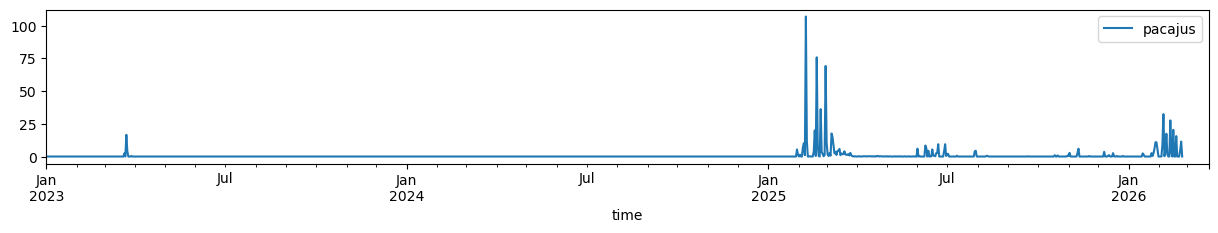

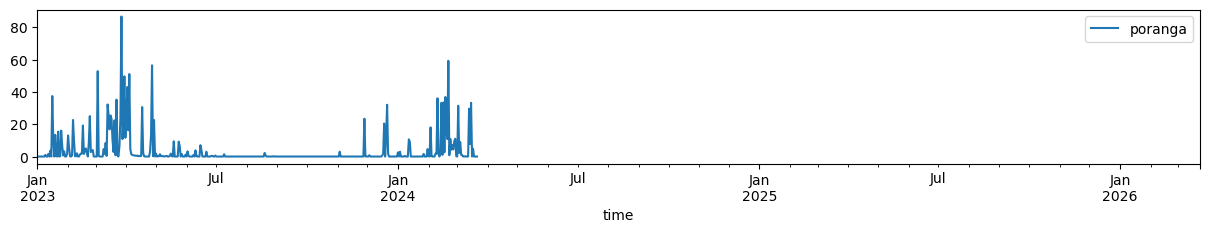

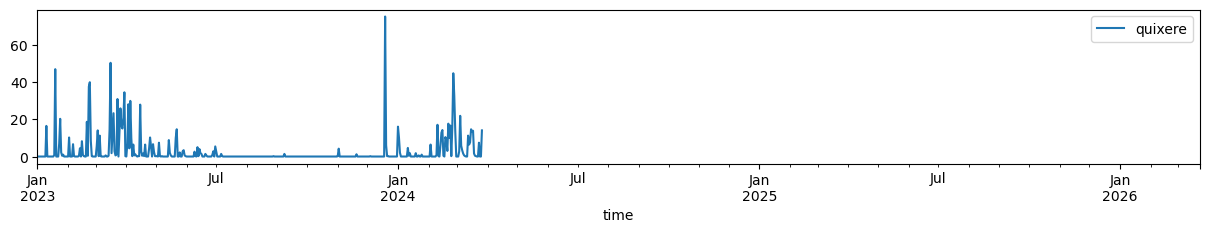

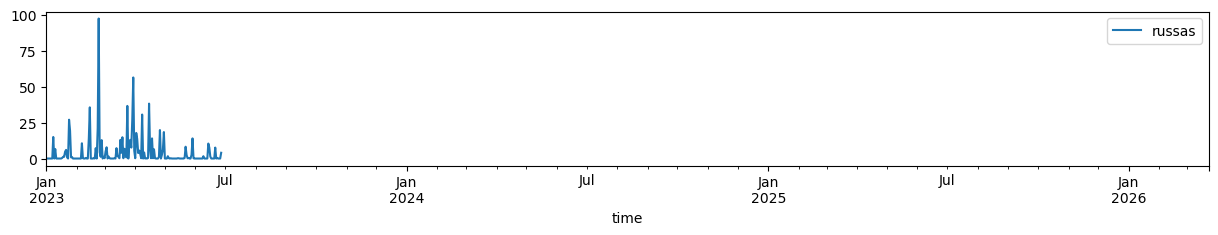

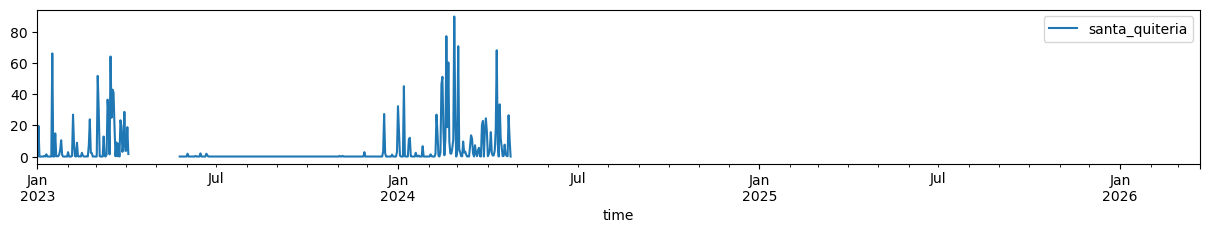

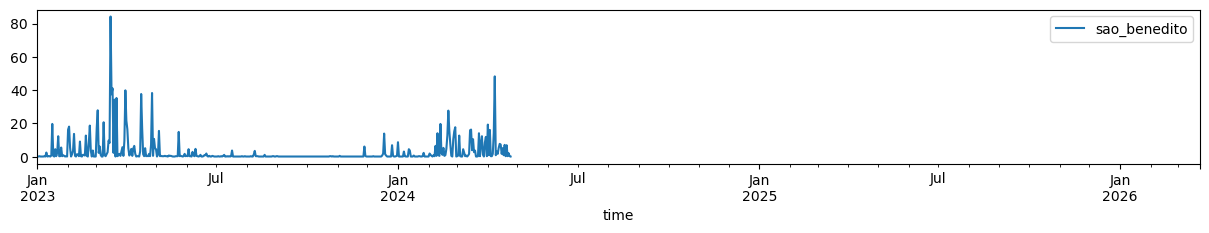

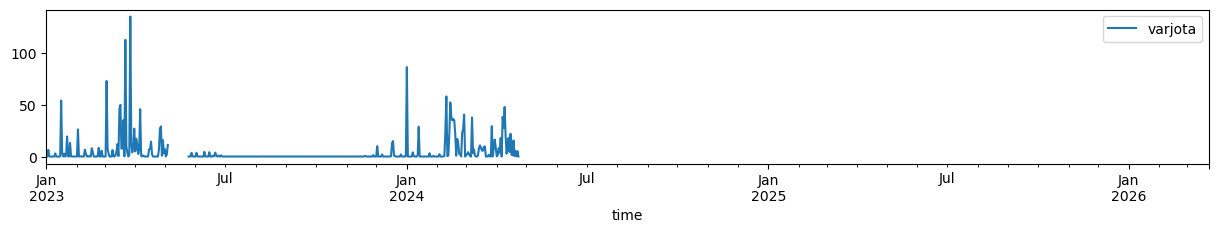

In [41]:
min_steps_per_day = np.int64((24*6)*0.8)

print(f'minimal accepted steps per day (0.8): {min_steps_per_day}')

df_daily_acc = gauges.data.groupby(pd.Grouper(freq='1D')).sum(min_count=min_steps_per_day)

for gauge in gauges.data.columns:
    df_daily_acc.loc['2023':, gauge].plot(label=gauge, figsize=(15,2))
    ax = plt.gca()
    ax.legend()
    plt.show()


In [62]:
gauges.calc_distance_to_point((lat0, lon0))
close_gauges = gauges.metadata.loc[gauges.metadata.distance_to_point < 180]

minimal accepted steps per day (0.8): 115


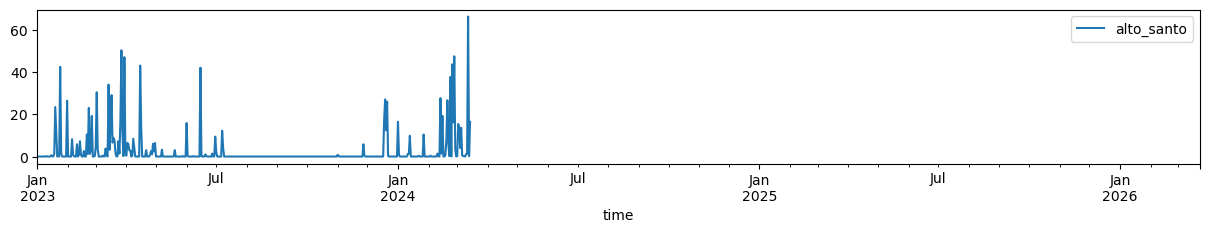

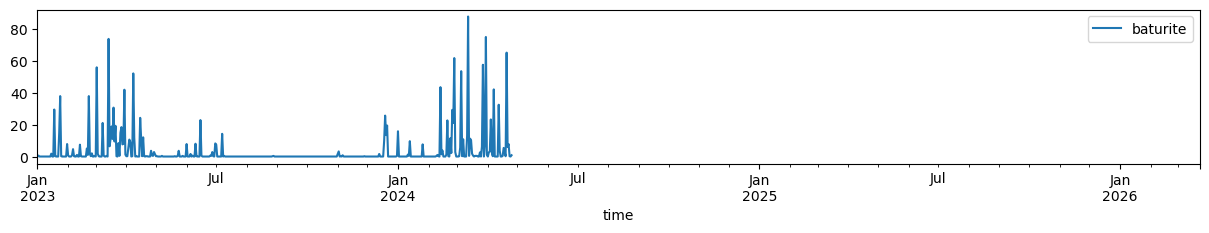

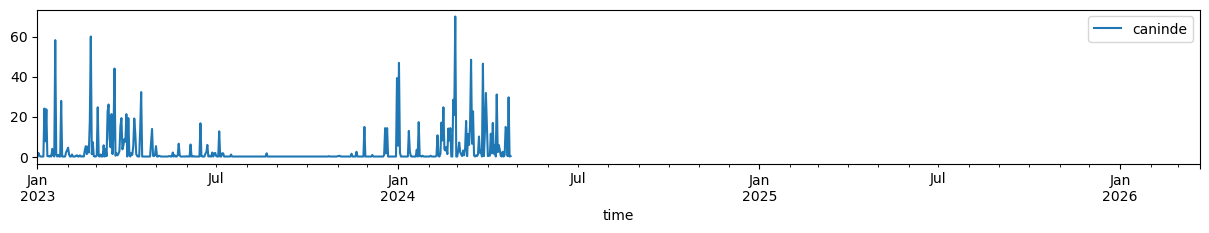

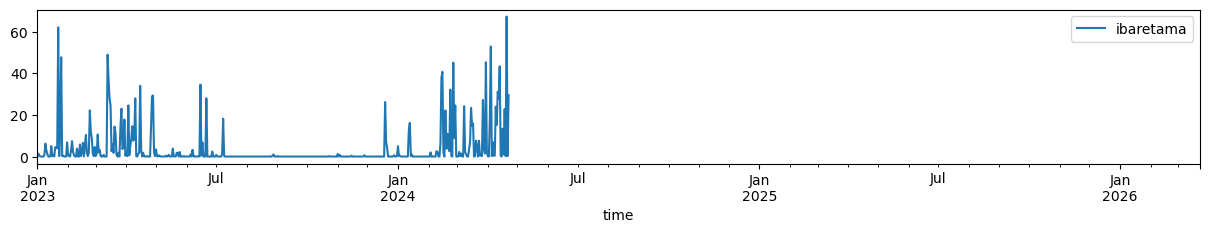

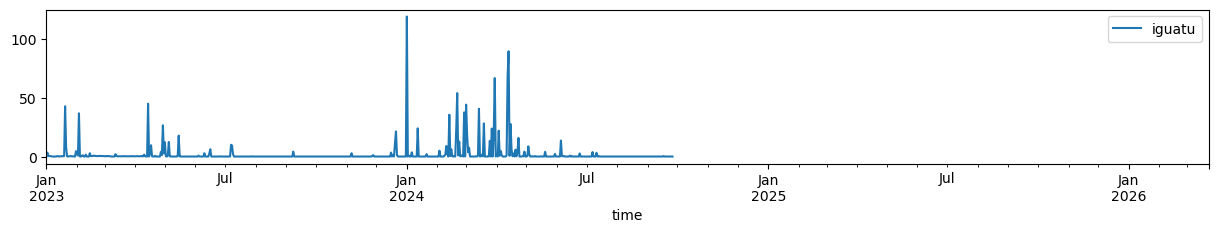

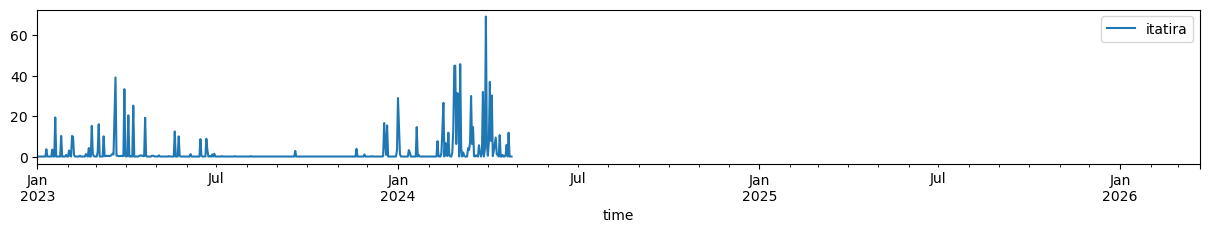

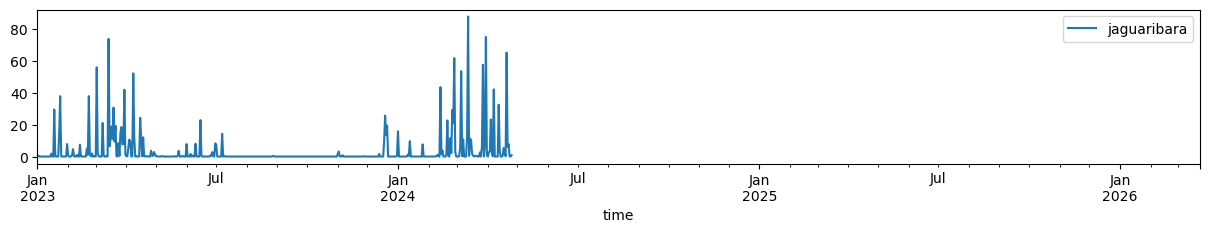

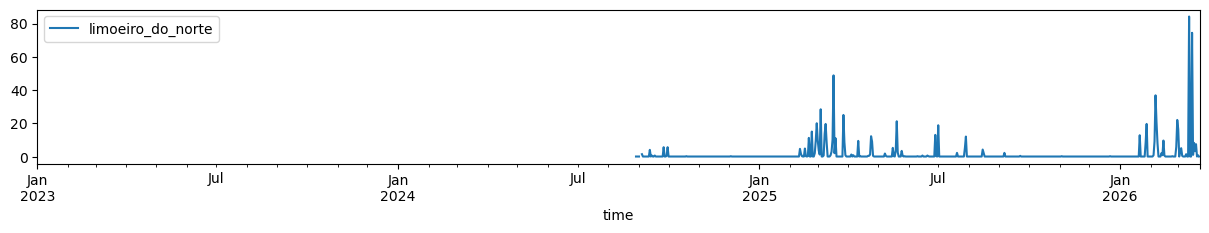

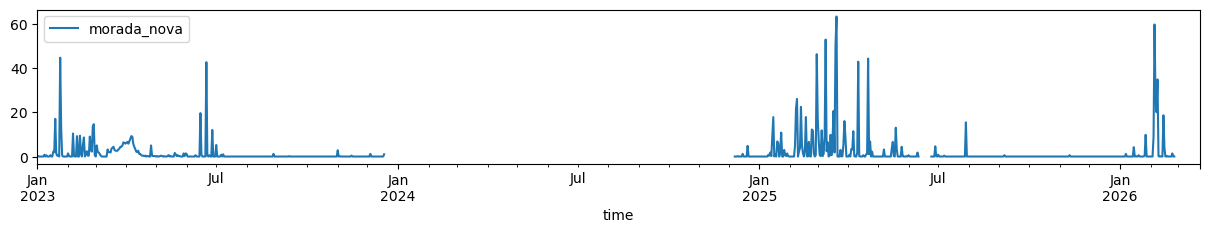

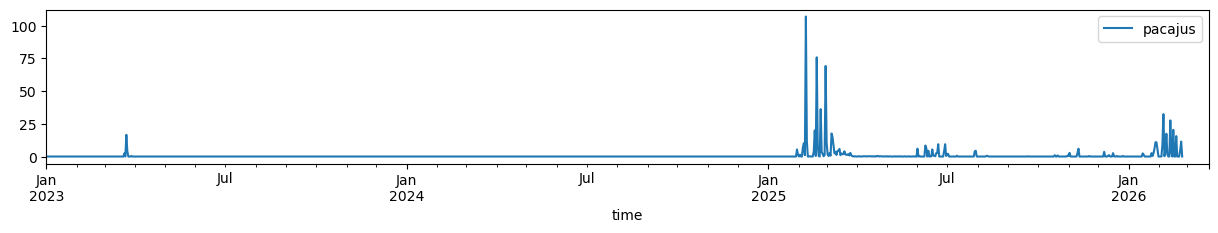

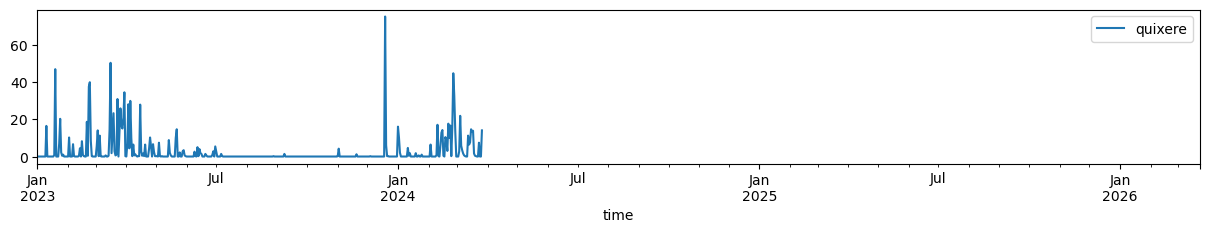

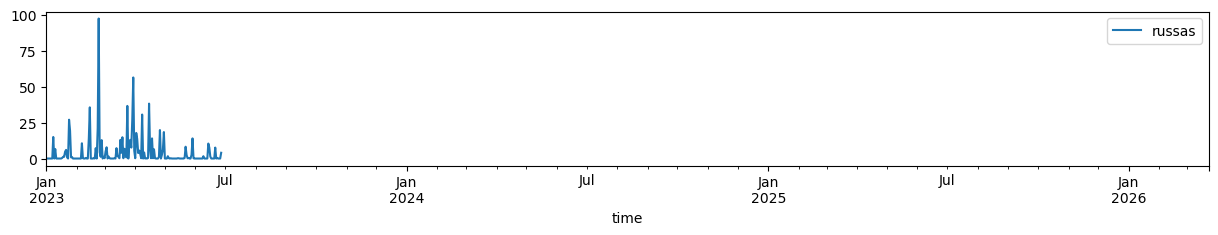

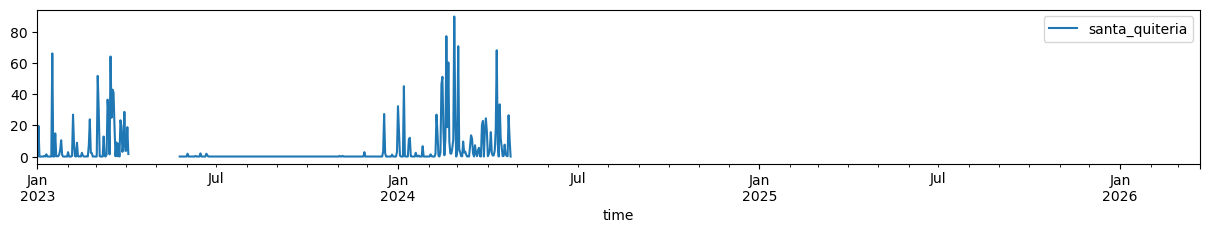

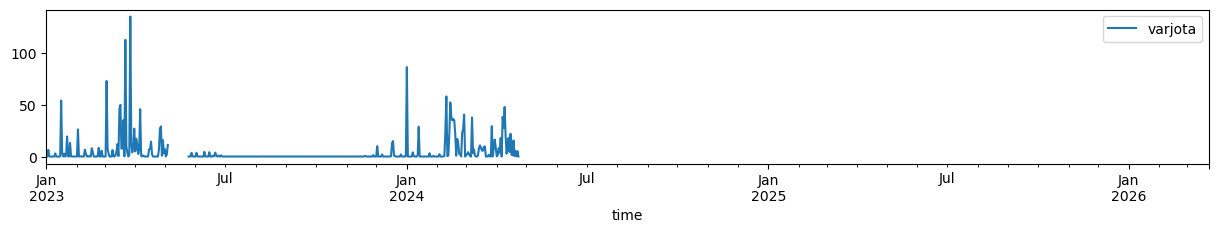

In [63]:
min_steps_per_day = np.int64((24*6)*0.8)

print(f'minimal accepted steps per day (0.8): {min_steps_per_day}')

df_daily_acc = gauges.data.groupby(pd.Grouper(freq='1D')).sum(min_count=min_steps_per_day)

for gauge in close_gauges.index:
    df_daily_acc.loc['2023':, gauge].plot(label=gauge, figsize=(15,2))
    ax = plt.gca()
    ax.legend()
    plt.show()


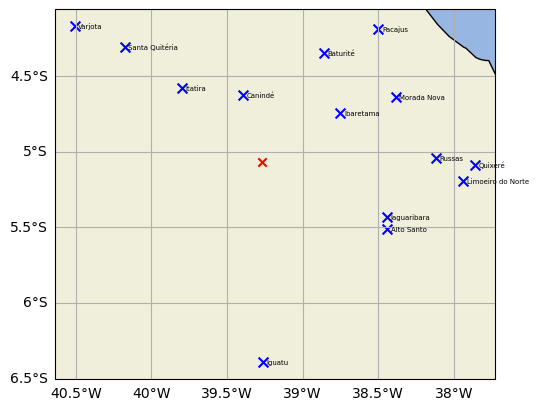

In [64]:
gvis.plot_simple_map()
ax = plt.gca()
gvis.plot_gauge_network(close_gauges, display_names=True)
ax.scatter(lon0, lat0, marker='x', c='r')

In [65]:
close_gauges_data = gauges.data.loc['2023':, close_gauges.index]
close_acc = close_gauges_data.groupby(pd.Grouper(freq='1D')).sum(min_count=min_steps_per_day)
close_acc.loc[(close_acc > 20).sum(axis=1)>=1].shape
dates = set(close_acc.loc[(close_acc > 20).sum(axis=1)>=1].index.tolist())

print(dates)

{Timestamp('2025-02-19 00:00:00'), Timestamp('2023-03-26 00:00:00'), Timestamp('2024-02-21 00:00:00'), Timestamp('2024-02-26 00:00:00'), Timestamp('2026-03-15 00:00:00'), Timestamp('2023-12-18 00:00:00'), Timestamp('2023-02-14 00:00:00'), Timestamp('2024-04-05 00:00:00'), Timestamp('2023-04-08 00:00:00'), Timestamp('2024-02-28 00:00:00'), Timestamp('2024-01-12 00:00:00'), Timestamp('2024-01-01 00:00:00'), Timestamp('2023-03-27 00:00:00'), Timestamp('2023-03-19 00:00:00'), Timestamp('2023-01-24 00:00:00'), Timestamp('2025-04-21 00:00:00'), Timestamp('2024-04-12 00:00:00'), Timestamp('2024-04-10 00:00:00'), Timestamp('2024-02-16 00:00:00'), Timestamp('2023-01-19 00:00:00'), Timestamp('2024-01-13 00:00:00'), Timestamp('2023-02-23 00:00:00'), Timestamp('2023-04-14 00:00:00'), Timestamp('2024-04-13 00:00:00'), Timestamp('2023-03-24 00:00:00'), Timestamp('2023-03-21 00:00:00'), Timestamp('2023-04-27 00:00:00'), Timestamp('2023-01-20 00:00:00'), Timestamp('2023-01-16 00:00:00'), Timestamp('20

In [66]:
dates_radar = set(df.loc[df.completion>95].index.tolist())
print(dates_radar)

{Timestamp('2024-06-16 00:00:00'), Timestamp('2024-10-21 00:00:00'), Timestamp('2025-09-11 00:00:00'), Timestamp('2024-02-26 00:00:00'), Timestamp('2025-04-24 00:00:00'), Timestamp('2024-07-15 00:00:00'), Timestamp('2025-08-12 00:00:00'), Timestamp('2024-03-09 00:00:00'), Timestamp('2024-10-31 00:00:00'), Timestamp('2024-11-11 00:00:00'), Timestamp('2024-07-14 00:00:00'), Timestamp('2024-04-05 00:00:00'), Timestamp('2024-10-19 00:00:00'), Timestamp('2023-06-04 00:00:00'), Timestamp('2026-05-14 00:00:00'), Timestamp('2023-05-27 00:00:00'), Timestamp('2025-08-23 00:00:00'), Timestamp('2024-07-16 00:00:00'), Timestamp('2025-08-18 00:00:00'), Timestamp('2023-05-29 00:00:00'), Timestamp('2025-12-21 00:00:00'), Timestamp('2024-08-14 00:00:00'), Timestamp('2024-09-21 00:00:00'), Timestamp('2024-05-04 00:00:00'), Timestamp('2025-01-09 00:00:00'), Timestamp('2025-01-30 00:00:00'), Timestamp('2024-08-07 00:00:00'), Timestamp('2023-05-28 00:00:00'), Timestamp('2026-01-17 00:00:00'), Timestamp('20

In [72]:
chosen_dates = sorted(list(dates_radar.intersection(dates)))

In [105]:
gauges_chosen_dates_data = pd.concat([close_gauges_data.loc[str(i.date()), :] for i in chosen_dates])

In [117]:
gauges_chosen_dates_data.resample('24h', label='left').sum(min_count=120)

id,alto_santo,baturite,caninde,ibaretama,iguatu,itatira,jaguaribara,limoeiro_do_norte,morada_nova,pacajus,quixere,russas,santa_quiteria,varjota
time,,,,,,,,,,,,,,
2023-04-01,0.4,0.2,21.200000,2.2,0.2,0.0,0.2,NaN,6.2,0.0,0.0,0.2,3.8,5.0
2023-04-02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2023-04-03,5.8,5.6,19.199999,24.6,0.4,20.4,5.6,NaN,5.8,0.0,28.0,13.6,1.6,11.6
2023-04-04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2023-04-05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-03-11,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2026-03-12,NaN,NaN,NaN,NaN,NaN,NaN,NaN,84.2,NaN,NaN,NaN,NaN,NaN,NaN
2026-03-13,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [119]:
# Daily rainfall and gauge coverage (10-minute data)
daily = gauges_chosen_dates_data.resample('1D')

rain = daily.sum(min_count=1)
coverage = daily.count() / 144

# At least one gauge with rain and >= 95% coverage
rainy_days = ((rain > 0) & (coverage >= 0.95)).any(axis=1)

chosen_dates = rainy_days[rainy_days].index

In [121]:
# Daily accumulated rainfall per gauge
daily = gauges_chosen_dates_data.resample('1D').sum(min_count=1)

# Conditional mean: exclude dry gauges
conditional_mean = daily.where(daily > 0).mean(axis=1)

# Select days exceeding 30 mm
chosen_dates = conditional_mean[conditional_mean > 30].index

print(f"{len(chosen_dates)} rainy days selected")

11 rainy days selected


<Axes: xlabel='time'>

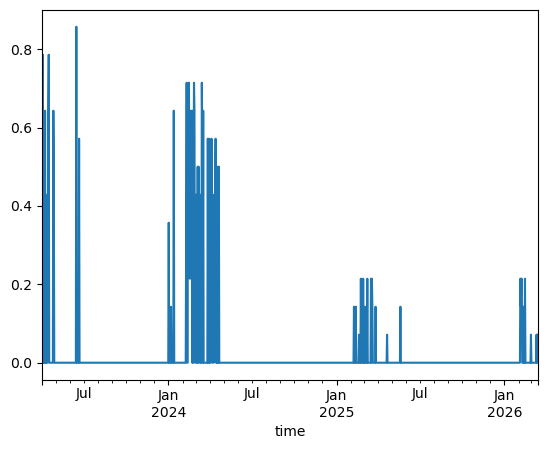

In [ ]:
(pd.concat([close_gauges_data.loc[str(i.date()), :] for i in chosen_dates]).groupby(pd.Grouper(freq='1D')).sum(min_count=120)>0.5).mean(axis=1).plot()

In [124]:
close_gauges_data.groupby(pd.Grouper(freq='30min')).sum().loc[str(date.date())]

id,alto_santo,baturite,caninde,ibaretama,iguatu,itatira,jaguaribara,limoeiro_do_norte,morada_nova,pacajus,quixere,russas,santa_quiteria,varjota
time,,,,,,,,,,,,,,
2026-03-15 00:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2026-03-15 00:30:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2026-03-15 01:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2026-03-15 01:30:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2026-03-15 02:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2026-03-15 02:30:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2026-03-15 03:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2026-03-15 03:30:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2026-03-15 04:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [148]:
close_gauges.drop('baturite', inplace=True)
close_gauges_data.drop('baturite', axis=1, inplace=True)

/tmp/ipykernel_247150/676484267.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  close_gauges.drop('baturite', inplace=True)


In [185]:
dfs_rad = []
pairs_tot = []
dfs_gau = []
for date in chosen_dates:
    ds = xr.open_dataset(df.loc[date, 'path'])
    df_sts = rad_vals_at_stations(ds, close_gauges.index, gauges, 'rainfall_rate')
    #display(ds)
    #display(df_sts)
    resampling_time = pd.Timedelta('30min')
    df_sts_30min = df_sts.fillna(0).resample(resampling_time, label='left').mean() * (resampling_time/pd.Timedelta('1hour'))
    # Gauge rainfall accumulated over 30 minutes
    df_gau_30min = close_gauges_data.resample(resampling_time, label='left').sum(min_count=1).loc[str(date.date())]

    # Match station names
    df_rad_30min = df_sts_30min.rename(
        columns=lambda c: c.removesuffix('_rainfall_rate')
    )

    # Keep common stations and timestamps
    stations = df_rad_30min.columns.intersection(df_gau_30min.columns)

    rad, gau = df_rad_30min[stations].align(
        df_gau_30min[stations], join='inner'
    )

    # Retain valid rainy point-pixel pairs
    valid = (gau > 0) & rad.notna()

    pairs = pd.DataFrame({
        'gauge_mm': gau.where(valid).stack(),
        'radar_mm': rad.where(valid).stack()
    }).dropna()
    pairs_tot.append(pairs)
    pairs.index.names = ['time', 'station']
    dfs_rad.append(rad)
    dfs_gau.append(gau)

In [186]:
display(sutils.score_rbias(pd.concat(pairs_tot), 'gauge_mm'))

display(sutils.score_correlation(pd.concat(pairs_tot), 'gauge_mm'))

{'radar_mm': {'relative_bias': np.float64(-0.16100688846309696)}}

{'radar_mm': {'correlation': np.float64(0.5908353427955336)}}

In [187]:
pd.concat(pairs_tot)

gauge_mm  radar_mm
time                station                              
2024-02-27 01:30:00 caninde                 2.2  1.204331
2024-02-27 02:00:00 caninde                 0.6  0.000000
                    ibaretama               0.2  0.000000
2024-02-27 03:00:00 santa_quiteria          0.2  0.157759
2024-02-27 04:00:00 santa_quiteria          0.2  0.086000
...                                         ...       ...
2026-03-15 13:00:00 limoeiro_do_norte      19.2  3.424432
2026-03-15 13:30:00 limoeiro_do_norte      16.6  0.000000
2026-03-15 14:00:00 limoeiro_do_norte      11.8  0.000000
2026-03-15 14:30:00 limoeiro_do_norte       7.6  0.000000
2026-03-15 15:00:00 limoeiro_do_norte       1.0  0.000000

[458 rows x 2 columns]

[Text(-5.0, 0, '(2024-03-30 16:00:00, varjota)'),
 Text(0.0, 0, '(2024-02-27 06:00:00, varjota)'),
 Text(5.0, 0, '(2024-02-27 11:00:00, varjota)'),
 Text(10.0, 0, '(2024-02-27 13:30:00, varjota)'),
 Text(15.0, 0, '(2024-02-27 20:00:00, varjota)'),
 Text(20.0, 0, '(2024-03-27 14:00:00, varjota)'),
 Text(25.0, 0, '(2024-03-30 03:00:00, varjota)'),
 Text(30.0, 0, '(2024-03-30 17:00:00, varjota)'),
 Text(35.0, 0, '')]

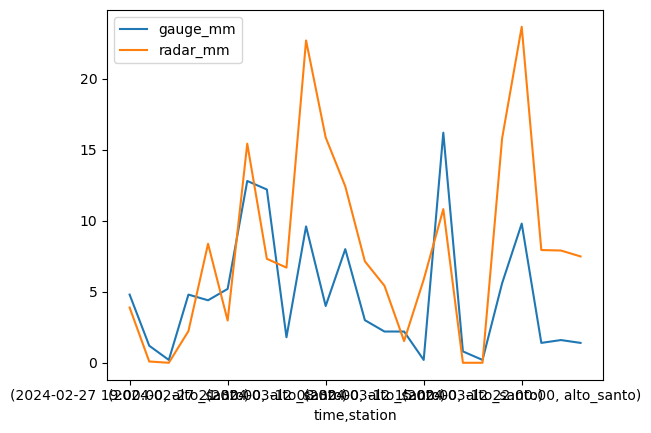

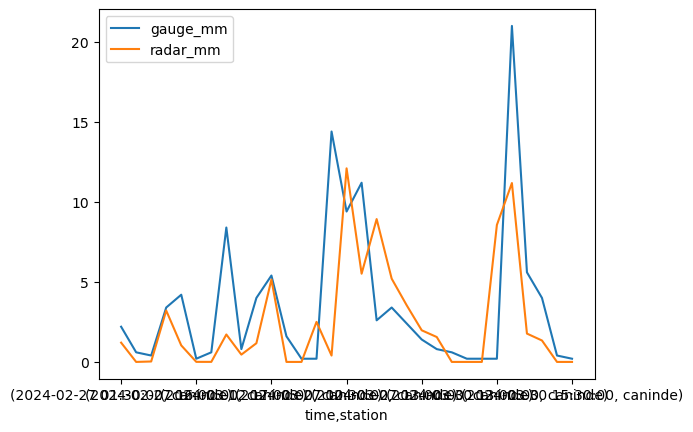

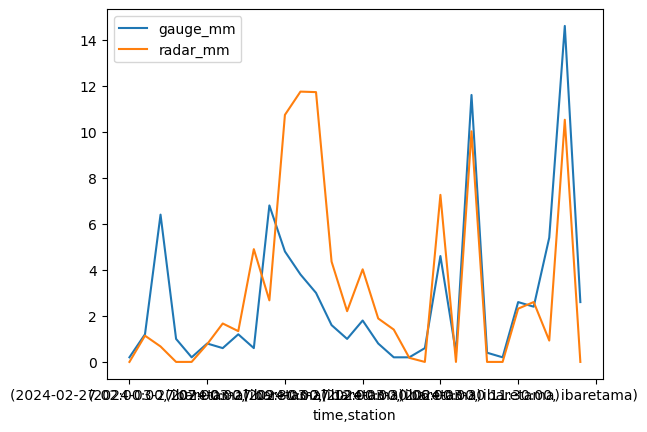

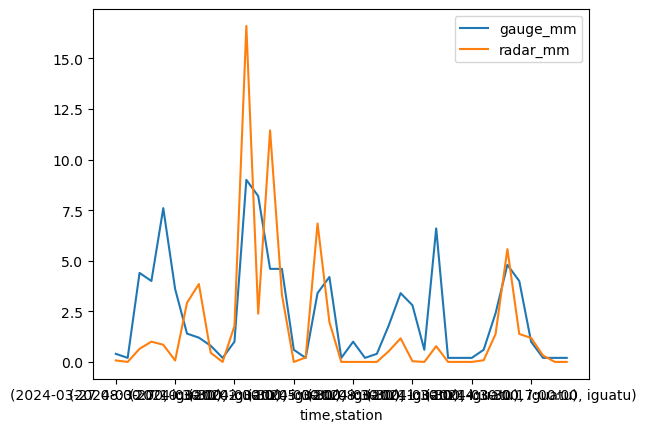

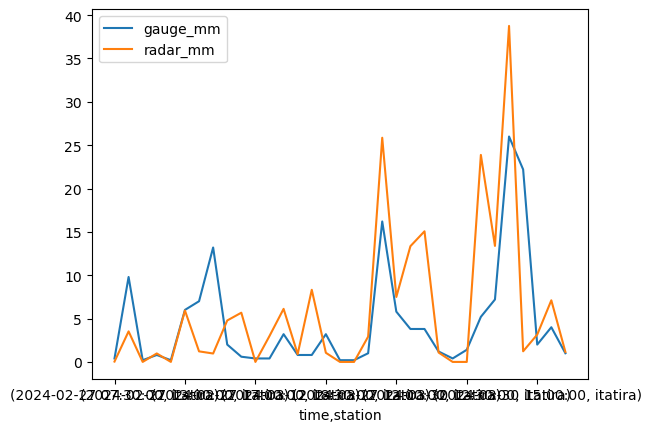

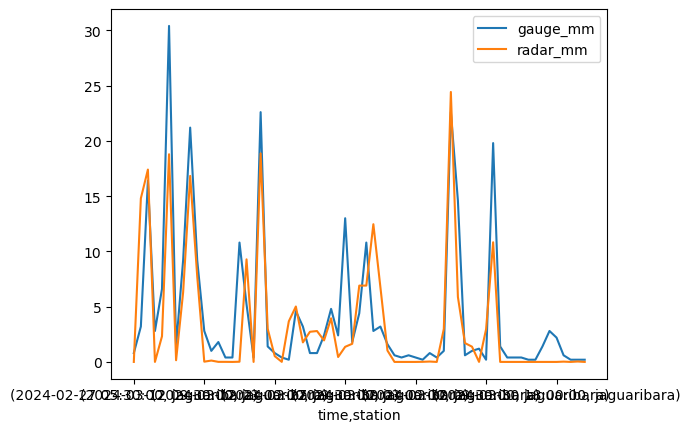

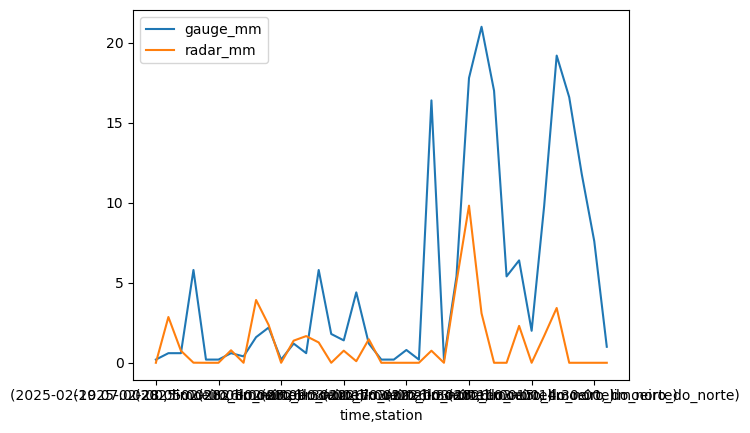

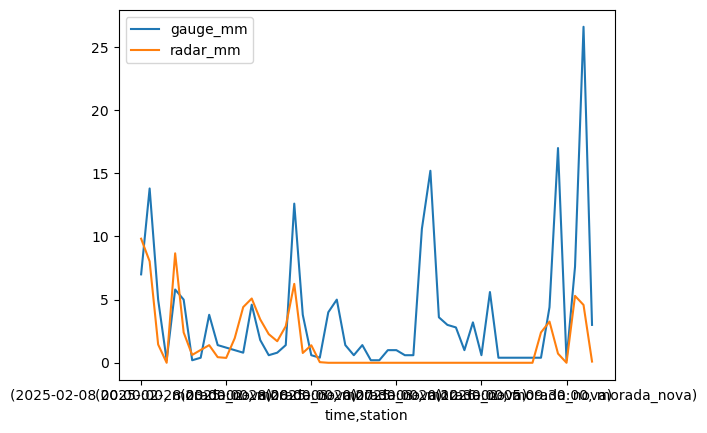

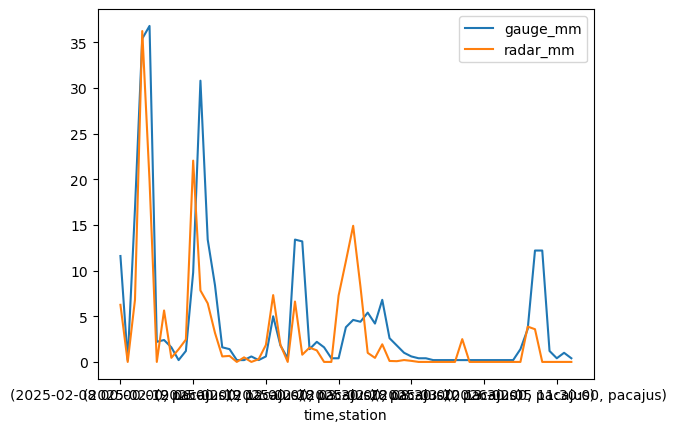

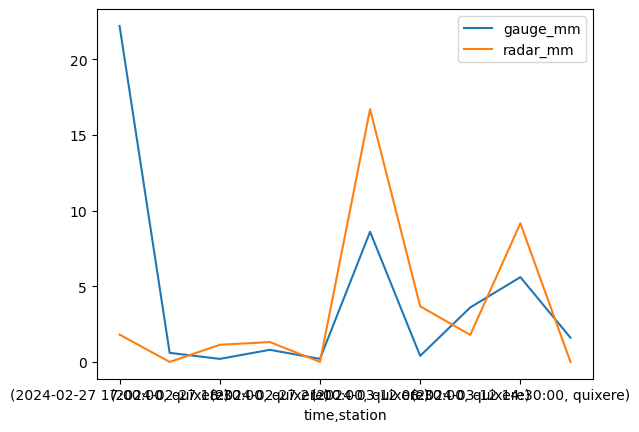

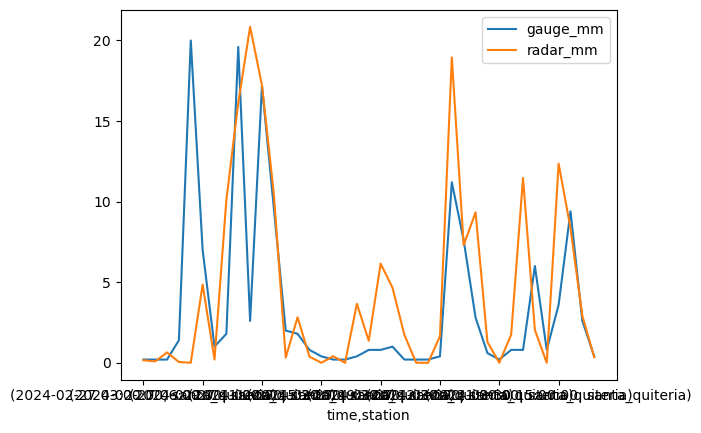

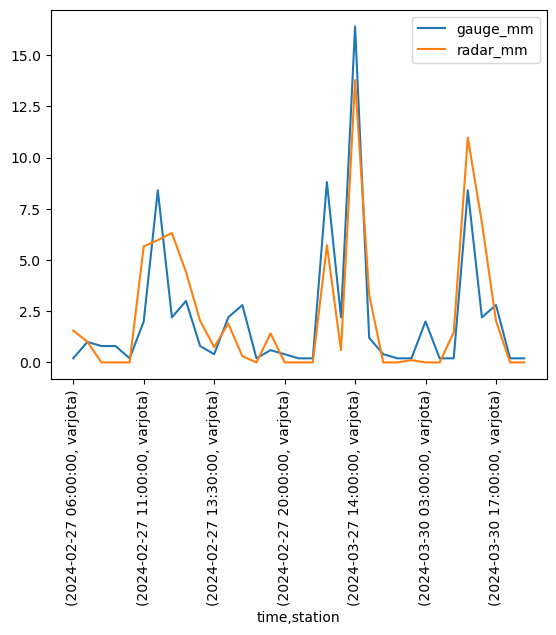

In [160]:
pd.concat(pairs_tot).groupby('station').plot()
ax = plt.gca()
ax.set_xticklabels(ax.get_xticklabels(), rotation=90)

<Axes: xlabel='time'>

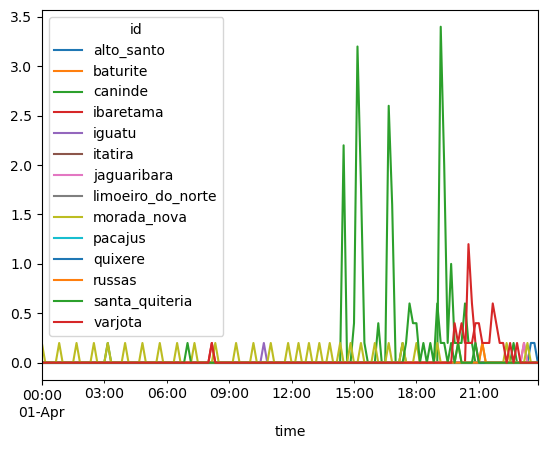

In [78]:
close_gauges_data.loc[str(date.date())].plot()